# 프로젝트: SentencePiece 사용하기
멋진 단어사전 만들기 — 5단계 프로젝트

> 2단계(데이터 다운로드 및 분석)의 `filtered_corpus`가 필요한 Step 2 셀은, 아래 '0. 데이터 준비' 셀로 대신 만들 수 있어요.

**Colab 사용법:** 런타임 → 런타임 유형 변경 → **T4 GPU**로 바꾸고, 바로 아래 설치 셀을 실행한 뒤 **런타임 → 세션 다시 시작**을 누르세요. 그다음 설치 셀은 건너뛰고 그 아래부터 순서대로 실행하면 돼요.

## Colab 설치 (처음 한 번만, 실행 후 세션 다시 시작)

In [1]:
!pip install -q konlpy sentencepiece
%cd /content
!git clone -q https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd /content/Mecab-ko-for-Google-Colab
!bash install_mecab-ko_on_colab_light_220429.sh
%cd /content

/content
/content/Mecab-ko-for-Google-Colab
Installing konlpy.....
Done
Installing mecab-0.996-ko-0.9.2.tar.gz.....
from https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
--2026-11-05 04:20:48--  https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
Resolving bitbucket.org (bitbucket.org)... 13.200.41.134, 13.200.41.135, 13.200.41.136, ...
Connecting to bitbucket.org (bitbucket.org)|13.200.41.134|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-05 04:20:49 ERROR 404: Not Found.

Done
Unpacking mecab-0.996-ko-0.9.2.tar.gz.......
Done
Change Directory to mecab-0.996-ko-0.9.2.......
install_mecab-ko_on_colab_light_220429.sh: line 23: cd: mecab-0.996-ko-0.9.2/: No such file or directory
installing mecab-0.996-ko-0.9.2.tar.gz........
configure
make
make check
make install
ldconfig
Done
Change Directory to /content
from https://bitbucket.org/eunjeon/mecab-ko-dic/downloads/mecab-ko-dic-2.1.1-20180720.tar.gz
--20

In [2]:
%cd /content
import torch
from torch.nn.utils.rnn import pad_sequence
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import konlpy
print(torch.__version__)
print(np.__version__)
print(matplotlib.__version__)
print(konlpy.__version__)

/content
2.11.0+cu130
2.4.6
3.10.0
0.6.0


## 0. 데이터 준비 (2단계와 같은 정제: 중복 제거, 길이 10 이상 150 미만)

In [3]:
import os
if not os.path.exists('korean-english-park.train.ko'):
    !wget -q https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
    !tar -xzf korean-english-park.train.tar.gz

with open('korean-english-park.train.ko', 'r', encoding='utf-8') as f:
    raw = f.read().splitlines()
print('원본:', len(raw))

cleaned_corpus = list(set(raw))
filtered_corpus = [s for s in cleaned_corpus if 10 <= len(s) < 150]
print('정제 후:', len(filtered_corpus))

원본: 94123
정제 후: 76908


## Step 1. SentencePiece 설치

In [4]:
!pip install -q sentencepiece

## Step 2. SentencePiece 모델 학습

In [5]:
import sentencepiece as spm
temp_file = 'korean-english-park.train.ko.temp'
vocab_size = 8000

with open(temp_file, 'w', encoding='utf-8') as f:
    for row in filtered_corpus:
        f.write(str(row) + '\n')

spm.SentencePieceTrainer.Train(
    '--input={} --model_prefix=korean_spm --vocab_size={}'.format(temp_file, vocab_size)
)
!ls -l korean_spm*

-rw-r--r-- 1 root root 380936 Nov  5 04:23 korean_spm.model
-rw-r--r-- 1 root root 147830 Nov  5 04:23 korean_spm.vocab


In [6]:
s = spm.SentencePieceProcessor()
s.Load('korean_spm.model')

tokensIDs = s.EncodeAsIds('아버지가방에들어가신다.')
print(tokensIDs)
print(s.SampleEncodeAsPieces('아버지가방에들어가신다.', -1, 0.1))
print(s.DecodeIds(tokensIDs))

[1202, 10, 318, 6, 3748, 10, 287, 31, 4]
['▁아버지', '가', '방', '에', '들어', '가', '신', '다', '.']
아버지가방에들어가신다.


## Step 3. sp_tokenize() 함수
`EncodeAsIds` 결과(list)를 tensor로 바꿔야 `pad_sequence`가 동작해요.

In [7]:
def sp_tokenize(s, corpus, vocab_path='./korean_spm.vocab', max_len=None):
    tensor = []
    for sen in corpus:
        ids = s.EncodeAsIds(sen)
        if max_len:
            ids = ids[:max_len]
        tensor.append(torch.tensor(ids, dtype=torch.long))

    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab = f.readlines()

    word_index, index_word = {}, {}
    for idx, line in enumerate(vocab):
        word = line.split('\t')[0]
        word_index[word] = idx
        index_word[idx] = word

    tensor = pad_sequence(tensor, batch_first=True, padding_value=0)
    return tensor, word_index, index_word

tensor, word_index, index_word = sp_tokenize(s, filtered_corpus[:5])
print(tensor.shape)
print(tensor[0])

torch.Size([5, 50])
tensor([ 136,  347,    3,   13,  118,   58, 2689,    5, 2269,    7,  930,   13,
        6019, 2600,    5, 1433, 6785,   53,   87, 1833,  565, 3666,   16, 1497,
         970,    7, 4611,   37,   27,    4,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0])


## Step 4. 네이버 영화리뷰(NSMC) 감정 분석에 SentencePiece 적용
### 4-1. 데이터 준비

In [8]:
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

import pandas as pd
train_df = pd.read_table('ratings_train.txt').dropna().drop_duplicates(subset=['document'])
test_df  = pd.read_table('ratings_test.txt').dropna().drop_duplicates(subset=['document'])
print(len(train_df), len(test_df))

# 학습 시간을 줄이려면 샘플링 (전체로 하려면 두 줄 삭제)
train_df = train_df.sample(60000, random_state=42)
test_df  = test_df.sample(20000, random_state=42)

train_texts, train_labels = train_df['document'].tolist(), train_df['label'].values
test_texts,  test_labels  = test_df['document'].tolist(),  test_df['label'].values

146182 49157


### 4-2. 분류 모델 + 학습 함수

In [9]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
device = 'cuda' if torch.cuda.is_available() else 'cpu'

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def train_eval(X_train, y_train, X_test, y_test, vocab_size, epochs=4, bs=256):
    torch.manual_seed(42)
    model = LSTMClassifier(vocab_size).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    tr = DataLoader(TensorDataset(X_train, torch.tensor(y_train, dtype=torch.float)), batch_size=bs, shuffle=True)
    te = DataLoader(TensorDataset(X_test, torch.tensor(y_test, dtype=torch.float)), batch_size=bs)
    for ep in range(epochs):
        model.train()
        for xb, yb in tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
    model.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in te:
            pred = (model(xb.to(device)) > 0).float().cpu()
            correct += (pred == yb).sum().item()
    return correct / len(y_test)

### 4-3. SentencePiece (model_type × vocab_size)

In [10]:
MAX_LEN = 60
with open('nsmc_train.txt', 'w', encoding='utf-8') as f:
    for t in train_texts:
        f.write(t + '\n')

def run_spm(model_type, vocab_size):
    prefix = f'nsmc_{model_type}_{vocab_size}'
    spm.SentencePieceTrainer.Train(
        f'--input=nsmc_train.txt --model_prefix={prefix} --vocab_size={vocab_size} '
        f'--model_type={model_type} --pad_id=0 --unk_id=1 --bos_id=2 --eos_id=3'
    )
    sp = spm.SentencePieceProcessor()
    sp.Load(f'{prefix}.model')
    X_tr, wi, _ = sp_tokenize(sp, train_texts, f'{prefix}.vocab', MAX_LEN)
    X_te, _, _ = sp_tokenize(sp, test_texts, f'{prefix}.vocab', MAX_LEN)
    return train_eval(X_tr, train_labels, X_te, test_labels, len(wi))

results = {}
for mt in ['unigram', 'bpe']:
    for vs in [4000, 8000, 16000]:
        acc = run_spm(mt, vs)
        results[f'SPM-{mt}-{vs}'] = acc
        print(mt, vs, f'{acc:.4f}')

unigram 4000 0.8344
unigram 8000 0.8331
unigram 16000 0.8247
bpe 4000 0.8330
bpe 8000 0.8311
bpe 16000 0.8255


### 4-4. KoNLPy MeCab 비교

In [11]:
from konlpy.tag import Mecab
from collections import Counter
mecab = Mecab()

def morph_tokenize(texts, word_index=None, num_words=16000):
    toks = [mecab.morphs(t) for t in texts]
    if word_index is None:
        cnt = Counter(w for ts in toks for w in ts)
        word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(num_words - 2))}  # 0=pad, 1=unk
    seqs = [torch.tensor([word_index.get(w, 1) for w in ts][:MAX_LEN] or [1]) for ts in toks]
    return pad_sequence(seqs, batch_first=True, padding_value=0), word_index

X_tr_m, wi_m = morph_tokenize(train_texts)
X_te_m, _ = morph_tokenize(test_texts, wi_m)
results['MeCab'] = train_eval(X_tr_m, train_labels, X_te_m, test_labels, len(wi_m) + 2)
print('MeCab', f"{results['MeCab']:.4f}")

MeCab 0.8436


### 4-5. 결과 비교

In [12]:
result_df = pd.DataFrame(sorted(results.items(), key=lambda x: -x[1]), columns=['tokenizer', 'test_acc'])
result_df

,tokenizer,test_acc
0,MeCab,0.84355
1,SPM-unigram-4000,0.83440
2,SPM-unigram-8000,0.83315
3,SPM-bpe-4000,0.83305
4,SPM-bpe-8000,0.83110
5,SPM-bpe-16000,0.82550
6,SPM-unigram-16000,0.82470


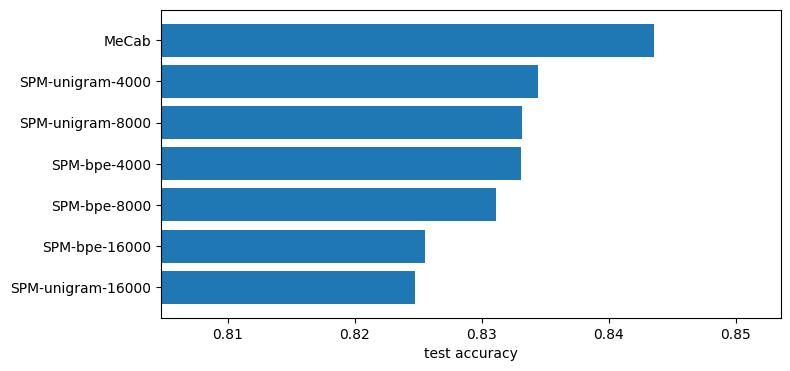

In [13]:
plt.figure(figsize=(8, 4))
plt.barh(result_df['tokenizer'], result_df['test_acc'])
plt.xlim(result_df['test_acc'].min() - 0.02, result_df['test_acc'].max() + 0.01)
plt.xlabel('test accuracy')
plt.gca().invert_yaxis()
plt.show()

## 회고

### 결과 요약 (NSMC, 학습 60,000 / 테스트 20,000, BiLSTM 4 epoch, A100)

| 토크나이저 | test acc |
|---|---|
| MeCab | 0.8436 |
| SPM unigram 4000 | 0.8344 |
| SPM unigram 8000 | 0.8332 |
| SPM bpe 4000 | 0.8331 |
| SPM bpe 8000 | 0.8311 |
| SPM bpe 16000 | 0.8255 |
| SPM unigram 16000 | 0.8247 |

### 분석
- 가장 좋은 토크나이저는 MeCab(84.4%)이었고, SentencePiece 중에서는 unigram 4000(83.4%)이 가장 좋았다. 차이는 약 1%p로 크지 않다.
- SentencePiece는 형태소 분석기 없이 데이터만으로 학습되는데도 사람이 만든 사전 기반의 MeCab과 거의 비슷한 성능을 냈다. 언어 지식 없이도 쓸 만한 토크나이저라는 점이 장점이다.
- MeCab이 조금 더 나은 이유는 감정을 나타내는 어근과 어미(예: 재밌, 없, 네요)를 문법적으로 깔끔하게 나눠주기 때문으로 보인다.
- vocab_size는 클수록 오히려 성능이 떨어졌다(4000 > 8000 > 16000). 학습 데이터가 6만 문장으로 많지 않아서 vocab이 커지면 등장 횟수가 적은 희귀 토큰이 늘고, 그 임베딩이 충분히 학습되지 못한 것으로 보인다.
- unigram과 bpe는 같은 vocab 크기에서 차이가 0.1~0.6%p 수준으로 거의 비슷했고, 4000·8000에서는 unigram이 조금 더 나았다.

### 느낀 점 / 다음에 해볼 것
- 전체 데이터(약 14만 문장)로 학습하면 큰 vocab의 성능이 달라질 수 있어 비교해보고 싶다.
- epoch 수를 늘리거나 더 큰 모델, 사전학습 임베딩(fastText)을 써서 두 방식의 차이를 다시 확인해볼 수 있다.